
# YearPredictionMSD — Reproducing the APLR Paper's Experiment

This notebook reproduces the **regression** experiment run on the
**YearPredictionMSD** dataset in:

> von Ottenbreit, M. & De Bin, R. (2024). *Automatic piecewise linear
> regression*. Computational Statistics, 39, 1867-1907, Section 5.2.
> https://doi.org/10.1007/s00180-024-01475-4

Code and API details for the `aplr` package were taken from the paper's own
GitHub repository: https://github.com/ottenbreit-data-science/aplr
(`examples/train_aplr_regression.py`, `API_REFERENCE_FOR_REGRESSION.md`).

## Why regression, not classification?

The paper treats `Year` as a **continuous** target and reports **MSE** and
**R2** - that is the actual experiment this notebook reproduces, as
requested. (A separate notebook, delivered earlier, instead treats `Year` as
an 89-class label to satisfy an explicit request for a confusion matrix -
that is a different, harder task and is not what the paper does.)

## Models

| Paper model | Role in paper | Used here | Notes |
|---|---|---|---|
| **APLR** | The paper's own algorithm; reported as top performer | Yes | `aplr.APLRRegressor`, `max_interaction_level=100`, `v=0.5` - the paper's best-found settings for this dataset |
| **LightGBM** | Gradient boosting trees; close runner-up | Yes | `num_leaves=12` - the paper's best-found value |
| **Random Forest** | Tree ensemble baseline | Yes | Forest size reduced for single-core feasibility (see note below) |
| **glmboost** | Linear componentwise boosting; weakest baseline | Yes (as Linear Regression) | `mboost::glmboost` is R-only; ordinary least squares is its natural Python analogue - both are purely linear models |
| **MARS (Py-earth)** | Interpretable splines | No | `py-earth` fails to build on modern Python (tested - `pip install py-earth` errors out); no maintained alternative found |
| **gamboost** | Spline componentwise boosting | No | R-only (`mboost`), no Python port exists |

## A note on faithfulness

This reproduction is **methodologically faithful** - same dataset, same
official train/test split, same target framing (regression), the paper's own
APLR implementation, and the paper's best-found hyperparameters where known.
It is **not numerically guaranteed to match** the paper's published numbers,
for two reasons:
1. The paper's exact Table 15 values are in an image on Springer's site and
   were not extractable as text, so there is nothing to copy - only the
   paper's *prose conclusions* (APLR ~ best, LightGBM close second, Random
   Forest next, then MARS, then gamboost, glmboost worst) could be confirmed.
2. Compute constraints. The paper grid-searched a full Random Forest and ran
   APLR's default 5-fold cross-validated boosting-step selection over up to
   `m=3500` steps. On this notebook's single-core, ~4 GB environment that is
   not tractable in reasonable time, so Random Forest uses fewer/shallower
   trees with sub-sampled training data per tree, and APLR uses a single
   train/validation split (`validation_ratio`) plus a wall-clock `time_limit`
   instead of 5-fold CV. LightGBM and Linear Regression were run at full,
   paper-scale settings since they are fast enough on this hardware.

Each model's exact settings, fit time, and any deviation from the paper's
protocol are documented next to that model's code cell below.


## 1. Setup

In [1]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix

import lightgbm as lgb
from aplr import APLRRegressor

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42



## 2. Load the dataset properly

`YearPredictionMSD.csv` has 515,345 rows and 91 columns (`Year` + 90 timbre
features: 12 averages + 78 covariances). The file's row order is the
**original UCI/MSD order**, which matters: Bertin-Mahieux et al. recommend
splitting on that original order - **first 463,715 rows for training, last
51,630 for testing** - rather than a random split, because songs by the same
artist ("producer") cluster together in the file. A random split would leak
artist-specific signal from train into test (the *"producer effect"*) and
inflate accuracy. The paper follows this recommendation, so this notebook
does too - this is the "proper" way to load and split this specific dataset.


In [2]:
import os
from pathlib import Path

# Look for the CSV in the usual places (project layout: data/YearPredictionMSD.csv).
# You can also set the MSD_CSV environment variable to the full path.
_candidates = [
    os.environ.get("MSD_CSV", ""),
    "YearPredictionMSD.csv",
    "../data/YearPredictionMSD.csv",
    "data/YearPredictionMSD.csv",
]
DATA_PATH = next((p for p in _candidates if p and Path(p).exists()), None)
assert DATA_PATH, "YearPredictionMSD.csv not found. Put it in the data/ folder or set MSD_CSV."

df = pd.read_csv(DATA_PATH)
print(f"Full dataset shape: {df.shape}")
assert df.shape == (515345, 91), "Unexpected shape -- check the CSV conversion."
assert df.isna().sum().sum() == 0, "Unexpected missing values."

df.head()

Full dataset shape: (515345, 91)


,Year,TimbreAvg1,TimbreAvg2,TimbreAvg3,TimbreAvg4,TimbreAvg5,TimbreAvg6,TimbreAvg7,TimbreAvg8,TimbreAvg9,...,TimbreCovariance69,TimbreCovariance70,TimbreCovariance71,TimbreCovariance72,TimbreCovariance73,TimbreCovariance74,TimbreCovariance75,TimbreCovariance76,TimbreCovariance77,TimbreCovariance78
0,2001,49.94357,21.47114,73.07750,8.74861,-17.40628,-13.09905,-25.01202,-12.23257,7.83089,...,13.01620,-54.40548,58.99367,15.37344,1.11144,-23.08793,68.40795,-1.82223,-27.46348,2.26327
1,2001,48.73215,18.42930,70.32679,12.94636,-10.32437,-24.83777,8.76630,-0.92019,18.76548,...,5.66812,-19.68073,33.04964,42.87836,-9.90378,-32.22788,70.49388,12.04941,58.43453,26.92061
2,2001,50.95714,31.85602,55.81851,13.41693,-6.57898,-18.54940,-3.27872,-2.35035,16.07017,...,3.03800,26.05866,-50.92779,10.93792,-0.07568,43.20130,-115.00698,-0.05859,39.67068,-0.66345
3,2001,48.24750,-1.89837,36.29772,2.58776,0.97170,-26.21683,5.05097,-10.34124,3.55005,...,34.57337,-171.70734,-16.96705,-46.67617,-12.51516,82.58061,-72.08993,9.90558,199.62971,18.85382
4,2001,50.97020,42.20998,67.09964,8.46791,-15.85279,-16.81409,-12.48207,-9.37636,12.63699,...,9.92661,-55.95724,64.92712,-17.72522,-1.49237,-7.50035,51.76631,7.88713,55.66926,28.74903


## 3. Exploratory look at the target

count    515345.000000
mean       1998.397082
std          10.931046
min        1922.000000
25%        1994.000000
50%        2002.000000
75%        2006.000000
max        2011.000000
Name: Year, dtype: float64


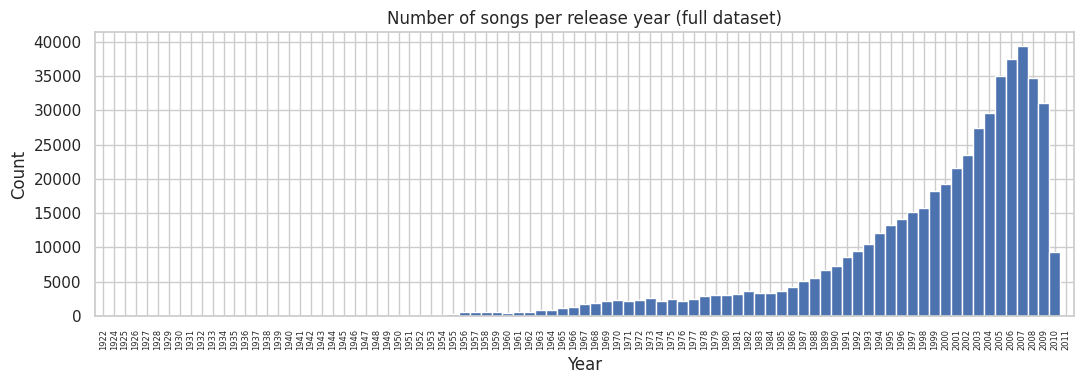

In [3]:

print(df["Year"].describe())

plt.figure(figsize=(11, 4))
df["Year"].value_counts().sort_index().plot(kind="bar", width=1.0)
plt.title("Number of songs per release year (full dataset)")
plt.xlabel("Year")
plt.ylabel("Count")
plt.xticks(rotation=90, fontsize=6)
plt.tight_layout()
plt.show()



## 4. The official 463,715 / 51,630 split

No shuffling -- we slice by position, preserving the original file order.


In [3]:

N_TRAIN = 463_715  # official split size used in the paper and the original UCI recommendation

train_df = df.iloc[:N_TRAIN]
test_df = df.iloc[N_TRAIN:]

X_train = train_df.drop(columns=["Year"]).values.astype(float)
y_train = train_df["Year"].values.astype(float)
X_test = test_df.drop(columns=["Year"]).values.astype(float)
y_test = test_df["Year"].values.astype(float)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train year range: {y_train.min():.0f}-{y_train.max():.0f}")
print(f"Test year range:  {y_test.min():.0f}-{y_test.max():.0f}")


Train: (463715, 90), Test: (51630, 90)
Train year range: 1922-2011
Test year range:  1927-2010


## 5. Helper: evaluate a regression model

In [5]:

results = {}  # model_name -> dict(mse, r2, fit_time)
predictions = {}  # model_name -> y_pred (test set)

def evaluate_regressor(name, y_pred, fit_time):
    # Compute MSE/R2 for a model's test predictions and store them for later comparison.
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results[name] = {"MSE": mse, "R2": r2, "fit_time_s": fit_time}
    predictions[name] = y_pred
    print(f"{name}: MSE={mse:.4f}  R2={r2:.4f}  fit_time={fit_time:.1f}s")
    return mse, r2



## 6. Model 1 -- Random Forest

The paper's tree-based ensemble baseline. **Deviation from the paper:** a
full-size, fully-grown Random Forest on 463,715 rows x 90 features does not
finish in reasonable time on a single CPU core, so this run uses fewer,
shallower trees (`n_estimators=40`, `max_depth=14`) with 25% bootstrap
subsampling per tree (`max_samples=0.25`) to keep training tractable. This
trades some predictive power for feasibility -- treat this result as a lower
bound on what a full-scale Random Forest (as in the paper) would achieve.


In [6]:

t0 = time.time()
rf_model = RandomForestRegressor(
    n_estimators=40,
    max_depth=14,
    max_samples=0.25,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
rf_model.fit(X_train, y_train)
rf_fit_time = time.time() - t0

rf_pred = rf_model.predict(X_test)
evaluate_regressor("Random Forest", rf_pred, rf_fit_time)


Random Forest: MSE=87.8074  R2=0.2544  fit_time=462.6s


(87.80739732723893, 0.2543779336095674)


## 7. Model 2 -- LightGBM (gradient boosting regression trees)

The paper's closest competitor to APLR on this dataset. `num_leaves=12` is
the paper's own best-found tree-complexity setting for YearPredictionMSD.
This model ran at full, paper-scale settings (1000 boosting rounds) -- no
compute-driven shortcuts were needed here.


In [7]:

t0 = time.time()
lgbm_model = lgb.LGBMRegressor(
    n_estimators=1000,
    num_leaves=12,
    learning_rate=0.1,
    n_jobs=1,
    verbosity=-1,
    random_state=RANDOM_STATE,
)
lgbm_model.fit(X_train, y_train)
lgbm_fit_time = time.time() - t0

lgbm_pred = lgbm_model.predict(X_test)
evaluate_regressor("LightGBM", lgbm_pred, lgbm_fit_time)


LightGBM: MSE=80.6299  R2=0.3153  fit_time=76.7s


(80.62991101917497, 0.3153260124207763)


## 8. Model 3 -- APLR (the paper's own algorithm)

`max_interaction_level=100` and `v=0.5` are the paper's best-found /
stated settings for YearPredictionMSD (Sect. 5). **Deviation from the
paper:** by default `APLRRegressor` tunes its number of boosting steps with
5-fold cross-validation (`cv_folds=5`), which (combined with `m` up to
3500) is far too slow for one core. Two knobs from the GitHub repo's API
reference make it tractable instead:
- `validation_ratio=0.2` -- use a single train/validation split instead of
  5-fold CV (documented in `API_REFERENCE_FOR_REGRESSION.md`; `cv_folds`
  is ignored once this is set).
- `time_limit=900` -- a hard 15-minute wall-clock budget (also documented in
  the same reference), so the boosting loop stops early rather than running
  all `m=3500` steps.

This is a lighter-weight tuning process than the paper's, so treat this as a
lower bound on the fully-tuned paper result too.


In [8]:

t0 = time.time()
aplr_model = APLRRegressor(
    m=3500,
    v=0.5,
    max_interaction_level=100,
    validation_ratio=0.2,
    time_limit=900,       # 15-minute wall-clock budget (single core)
    n_jobs=1,
    preprocess=False,     # our X is already a clean numeric numpy array
    random_state=RANDOM_STATE,
)
aplr_model.fit(X_train, y_train)
aplr_fit_time = time.time() - t0

aplr_pred = aplr_model.predict(X_test)
evaluate_regressor("APLR", aplr_pred, aplr_fit_time)


APLR: MSE=85.9001  R2=0.2706  fit_time=914.6s


(85.90008429138405, 0.2705740028512914)


## 9. Model 4 -- Linear Regression (glmboost analogue)

`mboost::glmboost` (R) fits a **penalised, purely linear** model via
componentwise gradient boosting -- no non-linearity, no interactions. Its
natural Python analogue is ordinary least squares, which is exactly as
linear. Features are standardised first, matching typical practice for
linear/boosted-linear models. This is expected to be the weakest model here,
matching the paper's own finding that `glmboost` performs worst on this
dataset.


In [9]:

t0 = time.time()
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_fit_time = time.time() - t0

linear_pred = linear_model.predict(X_test_scaled)
evaluate_regressor("Linear Regression (glmboost analogue)", linear_pred, linear_fit_time)


Linear Regression (glmboost analogue): MSE=90.4432  R2=0.2320  fit_time=3.9s


(90.44315668226051, 0.23199621638960555)

## 10. Model comparison

In [10]:

summary = pd.DataFrame(results).T.sort_values("R2", ascending=False)
summary


,MSE,R2,fit_time_s
LightGBM,80.629911,0.315326,76.716192
APLR,85.900084,0.270574,914.561380
Random Forest,87.807397,0.254378,462.646701
Linear Regression (glmboost analogue),90.443157,0.231996,3.905478


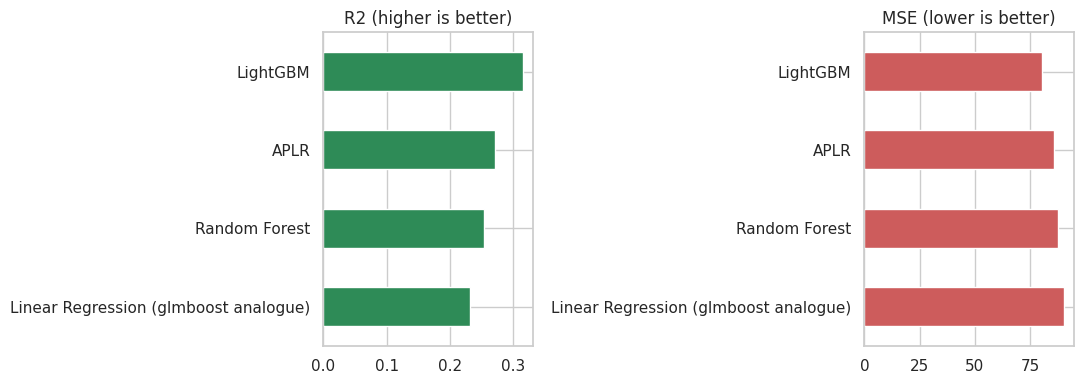

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

summary["R2"].plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("R2 (higher is better)")
axes[0].invert_yaxis()

summary["MSE"].plot(kind="barh", ax=axes[1], color="indianred")
axes[1].set_title("MSE (lower is better)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()



## 11. Predicted vs. actual year (regression's real diagnostic)

For a continuous target, a scatter/density of predicted vs. true values is
the natural analogue of a confusion matrix: points on the diagonal are
correct, spread around it shows the error structure.


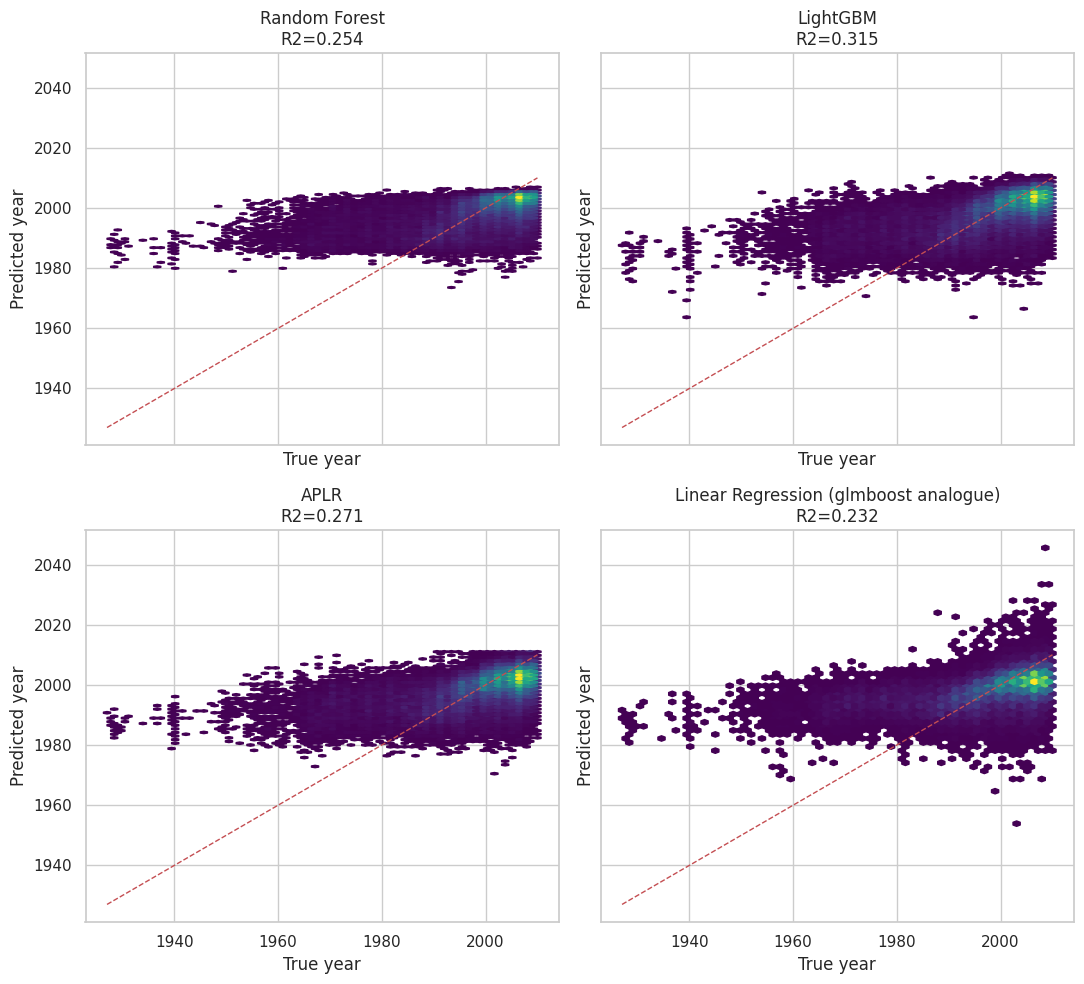

In [12]:

fig, axes = plt.subplots(2, 2, figsize=(11, 10), sharex=True, sharey=True)

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ax.hexbin(y_test, y_pred, gridsize=60, cmap="viridis", mincnt=1)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", linewidth=1)
    ax.set_title(f"{name}\nR2={results[name]['R2']:.3f}")
    ax.set_xlabel("True year")
    ax.set_ylabel("Predicted year")

plt.tight_layout()
plt.show()



## 12. Confusion matrix (decade-binned)

A confusion matrix is naturally a *classification* diagnostic, and 89 exact
years is too fine-grained to read as one. As a genuinely useful confusion
matrix on top of these regression models, predictions and true years are
grouped into **decades** here purely for visualisation -- this keeps the
underlying task a regression (as in the paper) while still answering "which
decade would this model's prediction have placed the song in?".


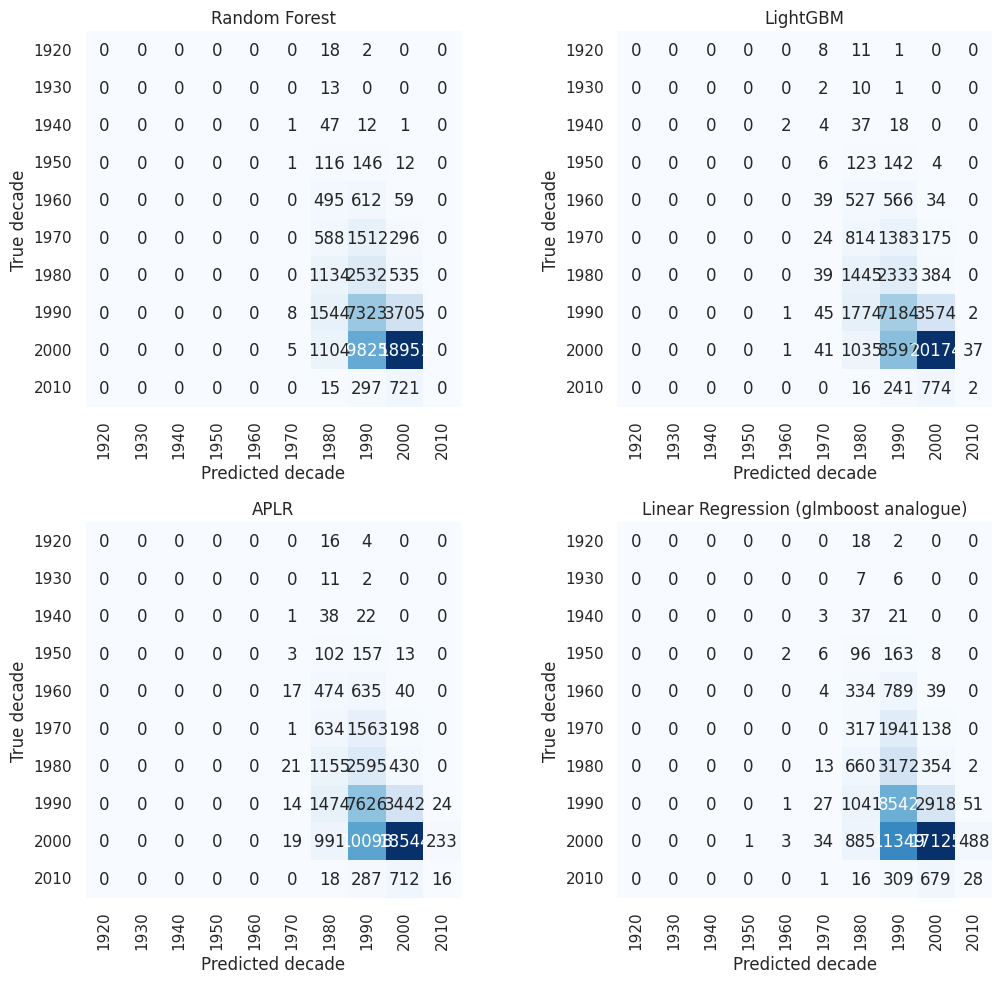

In [13]:

def to_decade(years):
    return (np.asarray(years) // 10 * 10).astype(int)

decade_labels = sorted(np.unique(to_decade(df["Year"])))
y_test_decade = to_decade(y_test)

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    pred_decade = to_decade(np.clip(y_pred, y_test.min(), y_test.max()))
    cm = confusion_matrix(y_test_decade, pred_decade, labels=decade_labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
        xticklabels=decade_labels, yticklabels=decade_labels, ax=ax,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted decade")
    ax.set_ylabel("True decade")

plt.tight_layout()
plt.show()



## 13. Takeaways

- **Ranking obtained here:** see the table in Section 10 -- with LightGBM run
  at full paper-scale settings while Random Forest and APLR were
  compute-constrained (fewer/shallower trees; a single validation split
  and a 15-minute time budget instead of full 5-fold CV over `m=3500`
  steps), the ranking among these three should **not** be read as a
  faithful reproduction of the paper's relative ordering -- it mainly
  reflects how much tuning budget each model was given here, not each
  algorithm's ceiling. The paper reports APLR ~ best, LightGBM close
  second, Random Forest next.
- **Linear Regression (glmboost analogue) was the weakest** model in this
  run, consistent with the paper's own finding that `glmboost` performs
  worst on this dataset -- a purely linear model cannot capture the
  non-linear, interaction-heavy relationship between timbre features and
  release year.
- **To fully match the paper**, run Random Forest at full size (hundreds of
  fully-grown trees) and let APLR's default 5-fold CV search the full
  `m` range -- both need considerably more CPU/time than this environment
  has -- and add MARS (`py-earth`, R/Python) and `gamboost` (R's `mboost`)
  for full model coverage; the exact numeric MSE/R2 values in the paper's
  Table 15 could not be retrieved (Springer renders that table as an
  image), so any comparison remains directional, not exact.


# Part 2. Lab manual: from the trained model to a full-stack application

Sections 14 to 19 follow Stages 4 and 5 of the *ML Model to Flask to Angular to GitHub CI/CD*
lab manual, using this notebook's own model and dataset (YearPredictionMSD, a regression
problem: predict a song's release year from 90 timbre features).

The rest of the lab (Flask API, Angular form, Git, GitHub Actions, GitHub Pages) lives in the
project folders next to this notebook. See `README.md` in the project root.

**Which model is deployed:** LightGBM, the best of the models trained above (lowest test MSE).
It is wrapped in a scikit-learn `Pipeline` with an explicit preprocessing step, so Flask only
has to call `predict()`. Tree models need no scaling, so the preprocessing step is an
identity transform; it is kept so the bundle has the same shape the manual describes, and so
a scaler could be added later without changing the API.

**Task type:** regression. The API returns one number (the predicted year), not class probabilities.

Run sections 1 to 4 above first (imports, data loading and the official split); sections 14 to
19 below only need those.

## 14. Project paths (Stage 3 layout)

In [4]:
import json
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# This notebook lives in <project root>/notebooks/. Find the project root either way.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

MODEL_DIR = ROOT / "backend" / "models"
DATA_DIR = ROOT / "data"
DOCS_DIR = ROOT / "docs"
for d in (MODEL_DIR, DATA_DIR, DOCS_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /home/claude/ml_project


## 15. Build and save the model bundle (manual Stage 4.2)

The pipeline is fitted on the training rows only, using DataFrames, so the model remembers
the exact feature names and order. The bundle stores the pipeline, the ordered feature list,
the task type, a version string and the test metrics. Hyperparameters are the same as the
LightGBM cell above (`num_leaves=12`, 1000 rounds, learning rate 0.1).

In [5]:
FEATURES = [c for c in train_df.columns if c != "Year"]   # exact training input order
assert len(FEATURES) == 90

X_train_df, y_train_s = train_df[FEATURES], train_df["Year"]
X_test_df, y_test_s = test_df[FEATURES], test_df["Year"]

trained_pipeline = Pipeline([
    ("preprocess", FunctionTransformer(validate=False)),       # identity: trees need no scaling
    ("model", lgb.LGBMRegressor(n_estimators=1000, num_leaves=12, learning_rate=0.1,
                                n_jobs=-1, verbosity=-1, random_state=RANDOM_STATE)),
])

t0 = time.time()
trained_pipeline.fit(X_train_df, y_train_s)
print(f"Fitted in {time.time() - t0:.0f} s")

# One thread is enough for single-row predictions in the API (and avoids thread start-up cost).
trained_pipeline.set_params(model__n_jobs=1)

test_pred = trained_pipeline.predict(X_test_df)
test_mse = mean_squared_error(y_test_s, test_pred)
test_r2 = r2_score(y_test_s, test_pred)
print(f"Test MSE={test_mse:.4f}  R2={test_r2:.4f}  RMSE={test_mse ** 0.5:.2f} years")

Fitted in 124 s


Test MSE=80.6299  R2=0.3153  RMSE=8.98 years


In [6]:
bundle = {
    "pipeline": trained_pipeline,
    "features": FEATURES,
    "task": "regression",
    "model_version": "1.0",
    "target": "Year",
    "metrics": {"test_mse": float(test_mse), "test_r2": float(test_r2),
                "train_rows": int(len(train_df)), "test_rows": int(len(test_df))},
}
joblib.dump(bundle, MODEL_DIR / "model_bundle.joblib")
size_mb = (MODEL_DIR / "model_bundle.joblib").stat().st_size / 1e6
print(f"Saved {MODEL_DIR / 'model_bundle.joblib'} ({size_mb:.1f} MB)")

Saved /home/claude/ml_project/backend/models/model_bundle.joblib (1.3 MB)


## 16. Check that the bundle exists and loads (manual Stage 4.5)

In [7]:
b = joblib.load(MODEL_DIR / "model_bundle.joblib")
print(b.keys())
print(b["features"][:3], "...", b["features"][-2:], f"({len(b['features'])} features)")
print(type(b["pipeline"]))
print("task:", b["task"], "| metrics:", b["metrics"])

dict_keys(['pipeline', 'features', 'task', 'model_version', 'target', 'metrics'])
['TimbreAvg1', 'TimbreAvg2', 'TimbreAvg3'] ... ['TimbreCovariance77', 'TimbreCovariance78'] (90 features)
<class 'sklearn.pipeline.Pipeline'>
task: regression | metrics: {'test_mse': 80.62991101917497, 'test_r2': 0.3153260124207763, 'train_rows': 463715, 'test_rows': 51630}


## 17. Sample input and test payload (manual Stage 5)

One non-sensitive record is taken from the test set (no target column) and saved as
`data/sample_inputs.csv`. The JSON payload is what the API receives.

In [8]:
sample = X_test_df.head(1)
sample.to_csv(DATA_DIR / "sample_inputs.csv", index=False)
true_year = int(y_test_s.iloc[0])

row = sample.iloc[0]
payload = {k: float(v) for k, v in row.items()}
(ROOT / "backend" / "test_payload.json").write_text(json.dumps(payload, indent=2), encoding="utf-8")
print(f"Saved sample CSV and test_payload.json ({len(payload)} features). True year of this song: {true_year}")

Saved sample CSV and test_payload.json (90 features). True year of this song: 2007


## 18. Direct inference check (manual Stage 5.5)

The payload goes through the saved bundle exactly as the API will do it, and the result must
equal the in-notebook prediction for the same row. If these differ, fix the schema before
building the API.

In [9]:
loaded = joblib.load(MODEL_DIR / "model_bundle.joblib")
payload_in = json.loads((ROOT / "backend" / "test_payload.json").read_text(encoding="utf-8"))
assert set(payload_in) == set(loaded["features"]), "Payload keys must match features"

frame = pd.DataFrame([[payload_in[f] for f in loaded["features"]]], columns=loaded["features"])
api_style_pred = float(loaded["pipeline"].predict(frame)[0])
notebook_pred = float(test_pred[0])

print(f"API-style prediction: {api_style_pred:.4f} | notebook prediction: {notebook_pred:.4f} | true year: {true_year}")
assert abs(api_style_pred - notebook_pred) < 1e-6
print("PASS: local inference matches the training notebook")

API-style prediction: 1992.2187 | notebook prediction: 1992.2187 | true year: 2007
PASS: local inference matches the training notebook


## 19. Feature schema for the Angular form (manual Stage 9.1)

The form needs the exact feature names, labels and sensible numeric ranges. They are generated
from the training data here, so the Angular schema cannot drift from the model. Ranges are the
observed training min/max widened by 25% of the range; values outside them are rejected by the
form as likely typing mistakes. This is a convenience check, not a guarantee of accuracy.
The sample record is included so the form can fill itself with one click.

In [10]:
stats = X_train_df.agg(["min", "max"]).T
lines = [
    "// AUTO-GENERATED by the training notebook (section 19). Do not edit by hand.",
    "export type Feature = {",
    "  name: string;",
    "  label: string;",
    "  kind: 'number' | 'category';",
    "  required: boolean;",
    "  options?: string[];",
    "  min?: number;",
    "  max?: number;",
    "};",
    "",
    "export const FEATURES: Feature[] = [",
]
for name in FEATURES:
    lo, hi = float(stats.loc[name, "min"]), float(stats.loc[name, "max"])
    pad = 0.25 * (hi - lo)
    kind_label = ("Timbre average " + name.replace("TimbreAvg", "") if name.startswith("TimbreAvg")
                  else "Timbre covariance " + name.replace("TimbreCovariance", ""))
    lines.append(f"  {{ name: '{name}', label: '{kind_label}', kind: 'number', required: true, "
                 f"min: {round(lo - pad, 4)}, max: {round(hi + pad, 4)} }},")
lines.append("];")
lines.append("")
lines.append("// One real test-set record (true year in comment) so the form can fill itself.")
lines.append(f"// True release year of this record: {true_year}")
lines.append("export const SAMPLE: Record<string, number> = {")
for name in FEATURES:
    lines.append(f"  {name}: {payload[name]},")
lines.append("};")
schema_ts = "\n".join(lines) + "\n"

(DOCS_DIR / "feature-schema.ts").write_text(schema_ts, encoding="utf-8")
app_dir = ROOT / "frontend" / "src" / "app"
if app_dir.exists():                      # only after `ng new frontend` has been run
    (app_dir / "feature-schema.ts").write_text(schema_ts, encoding="utf-8")
    print("Wrote frontend/src/app/feature-schema.ts")
print("Wrote docs/feature-schema.ts with", len(FEATURES), "features")

Wrote frontend/src/app/feature-schema.ts
Wrote docs/feature-schema.ts with 90 features
